# Limpieza de las series diarias (346 cuencas, desde los datos crudos)

Documenta, regla por regla, cómo se pasa de `Hydromet_data_<id>.txt` crudo a la serie limpia. Todo se calcula desde `Camels col/`; el código de la limpieza es `codigo/limpiar_series.py`. **Las secciones 1 a 5 no descartan cuencas**; el descarte con las banderas de calidad está en la sección 6.

| Paso | Regla | Fuente |
|---|---|---|
| 1 | Calendario diario continuo; los días sin fila se agregan con `NaN` | — (requisito para rezagos y ventanas) |
| 2 | ETP de Hargreaves en lugar de la ETP del dataset | [2], [3] |
| 3a | Caudal `frozen`: racha de ≥ 30 días con el mismo valor | [1] Flat Line Test, [4] persistencia |
| 3b | Caudal `spike`: día aislado > 10 veces el mayor de sus dos vecinos (opción A, ver 3b) | [1] Spike Test |
| 4 | Descarte de cuencas con seis banderas (sección 6) | balance de masa; [1] para línea plana; criterio del equipo |

**Referencias**
1. NOAA IOOS, *Manual for Real-Time Quality Control of Stream Flow Observations*, versión 1.0, sept. 2018, DOI 10.25923/gszc-ha43. Pruebas 5 (Spike Test, p. A-17) y 7 (Flat Line Test, p. A-19).
2. G. H. Hargreaves y Z. A. Samani, "Reference crop evapotranspiration from temperature", *Applied Engineering in Agriculture*, vol. 1, n.º 2, pp. 96–99, 1985.
3. R. G. Allen, L. S. Pereira, D. Raes y M. Smith, *Crop evapotranspiration*, FAO Irrigation and Drainage Paper 56, 1998 (ecs. 21–25 y 52).
4. J. Estévez, P. Gavilán y J. V. Giráldez, "Guidelines on validation procedures for meteorological data from automatic weather stations", *Journal of Hydrology*, vol. 402, pp. 144–154, 2011.

**Límite de las fuentes.** [1] define las pruebas, pero deja los umbrales al criterio local del operador y sus ejemplos son para datos cada 15 minutos. Los umbrales de este notebook (30 días y 10×) no vienen de un libro: se justifican con los datos, en las secciones 3a y 3b.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "codigo"))
import limpiar_series as ls

RAW, OUT, PREVIA = ls.RAW, ls.OUT, ls.PREVIA
rutas = sorted(RAW.glob("Hydromet_data_*.txt"))
print(f"{len(rutas)} series crudas; limpieza previa de comparación: {PREVIA is not None}")
area = pd.read_csv(RAIZ / "Camels col/10_CAMELS_COL_Physiograpic_characteristics.csv", sep=";")
area.columns = area.columns.str.strip(); area = area.set_index("gauge_id")["area"]

346 series crudas; limpieza previa de comparación: True


## 1. Calendario continuo
Las series crudas no traen fila para los días sin dato. Se reindexa de la primera a la última fecha de cada serie, un día por fila. Los días agregados quedan con `NaN` en todas las variables (no se imputa: inventar lluvia o temperatura no se puede distinguir de un dato real) y con `Caudal_estado = no_data`.

In [2]:
filas = []
for r in rutas:
    a = pd.read_csv(r, sep="\t")
    a["Fecha"] = pd.to_datetime(a["Fecha"], format="%d/%m/%Y")
    n_cal = (a.Fecha.max() - a.Fecha.min()).days + 1
    filas.append(dict(gauge_id=int(r.stem.split("_")[-1]), filas_crudo=len(a), filas_calendario=n_cal, agregados=n_cal - len(a),
                      nulos_crudo=int(a.isna().sum().sum()), duplicadas=int(a.Fecha.duplicated().sum())))
cal = pd.DataFrame(filas)
print(f"Filas crudas: {cal.filas_crudo.sum():,}   con calendario continuo: {cal.filas_calendario.sum():,}   agregadas: {cal.agregados.sum():,} ({100 * cal.agregados.sum() / cal.filas_calendario.sum():.1f} %)")
print(f"Nulos en las series crudas: {cal.nulos_crudo.sum()}   fechas duplicadas: {cal.duplicadas.sum()}   cuencas con al menos un día agregado: {(cal.agregados > 0).sum()} de {len(cal)}")

Filas crudas: 4,072,868   con calendario continuo: 4,347,980   agregadas: 275,112 (6.3 %)
Nulos en las series crudas: 0   fechas duplicadas: 0   cuencas con al menos un día agregado: 345 de 346


## 2. ETP de Hargreaves
**Fórmula** ([2], [3] ec. 52), con la temperatura media $T_{mean}=(T_{max}+T_{min})/2$ en °C:

$$ET_0 = 0{,}0023\,(T_{mean}+17{,}8)\,\sqrt{T_{max}-T_{min}}\;R_a\cdot 0{,}408 \quad [\text{mm/día}]$$

La radiación extraterrestre $R_a$ (MJ m⁻² día⁻¹) sale de la latitud $\varphi$ y el día del año $J$ ([3] ecs. 21–25):

$$R_a=\frac{24\cdot 60}{\pi}\,G_{sc}\,d_r\,[\omega_s\sin\varphi\sin\delta+\cos\varphi\cos\delta\sin\omega_s],\quad G_{sc}=0{,}0820$$
$$d_r=1+0{,}033\cos\!\left(\tfrac{2\pi J}{365}\right),\quad \delta=0{,}409\sin\!\left(\tfrac{2\pi J}{365}-1{,}39\right),\quad \omega_s=\arccos[-\tan\varphi\tan\delta]$$

**Por qué se reemplaza la ETP del dataset.** FAO-56 recomienda Hargreaves cuando solo hay temperatura. Aquí además la ETP original está sobreestimada de forma sistemática (sección 2b). **Limitaciones:** Hargreaves es una aproximación y se recomienda validarla localmente frente a Penman-Monteith; la latitud es la de la estación de aforo (no el centroide de la cuenca), diferencia pequeña en Colombia por su baja latitud.

In [3]:
info = pd.read_csv(RAIZ / "Camels col/02_CAMELS_COL_Catchment_information.csv", sep=";", encoding="latin-1")
from pyproj import Transformer
lon, lat = Transformer.from_crs("ESRI:54004", "EPSG:4326", always_xy=True).transform(info.gauge_lon.values, info.gauge_lat.values)
lat_de = dict(zip(info.gauge_id, lat))
print(f"Latitud de las estaciones: {min(lat):.2f}° a {max(lat):.2f}°")

# sanidad: Ra en el ecuador debe estar entre 33 y 37 MJ/m2/día según la época
for doy, nombre in [(15, "15 ene"), (172, "21 jun"), (355, "21 dic")]:
    print(f"Ra a 0° el {nombre}: {ls.radiacion_extraterrestre(0.0, doy):.1f} MJ/m²/día  ({0.408 * ls.radiacion_extraterrestre(0.0, doy):.1f} mm/día)")

Latitud de las estaciones: -1.44° a 11.28°
Ra a 0° el 15 ene: 36.2 MJ/m²/día  (14.8 mm/día)
Ra a 0° el 21 jun: 33.4 MJ/m²/día  (13.6 mm/día)
Ra a 0° el 21 dic: 35.6 MJ/m²/día  (14.5 mm/día)


### 2b. Efecto sobre la ETP y la aridez
Se compara la ETP media del dataset con la de Hargreaves, y el índice de aridez (ETP / lluvia) con cada una.

In [4]:
filas = []
for r in rutas:
    gid = int(r.stem.split("_")[-1])
    a = pd.read_csv(r, sep="\t")
    a["Fecha"] = pd.to_datetime(a["Fecha"], format="%d/%m/%Y")
    h = ls.hargreaves(a, lat_de[gid])
    filas.append(dict(gauge_id=gid, etp_original=a.ETP_.mean(), etp_hargreaves=h.mean(), P=a.Precipitacion.mean()))
etp = pd.DataFrame(filas)
etp["cociente"] = etp.etp_hargreaves / etp.etp_original
etp["aridez_original"] = etp.etp_original / etp.P
etp["aridez_hargreaves"] = etp.etp_hargreaves / etp.P
print(f"Cociente Hargreaves / ETP original: mediana {etp.cociente.median():.2f}, rango {etp.cociente.min():.2f}–{etp.cociente.max():.2f}")
print(f"ETP media nacional: original {etp.etp_original.mean():.2f} mm/día, Hargreaves {etp.etp_hargreaves.mean():.2f} mm/día")
print(f"Cuencas con aridez > 1: {(etp.aridez_original > 1).sum()} con la ETP original, {(etp.aridez_hargreaves > 1).sum()} con Hargreaves (de {len(etp)})")

Cociente Hargreaves / ETP original: mediana 0.37, rango 0.35–0.39
ETP media nacional: original 8.72 mm/día, Hargreaves 3.23 mm/día
Cuencas con aridez > 1: 309 con la ETP original, 18 con Hargreaves (de 346)


**Lectura.** La ETP de Hargreaves equivale a cerca del 37 % de la original, con casi el mismo cociente en todas las cuencas: la original estaba sobreestimada de forma sistemática. Con la original, casi todo el país parece árido (aridez > 1), algo poco plausible en un país con regiones tan lluviosas.

## 3. Reglas para el caudal
Cada día de caudal recibe un estado. Los días `frozen` y `spike` quedan con `Caudal = NaN` (no se imputan) y se excluyen de la pérdida y las métricas.

| Estado | Regla | Parámetro |
|---|---|---|
| `no_data` | día agregado por el calendario | — |
| `frozen` | racha de días consecutivos con exactamente el mismo caudal (> 0 y sin `NaN`) | `FROZEN_MIN = 30` |
| `spike` | $Q_t > k \cdot \max(Q_{t-1}, Q_{t+1})$ con ese máximo > 0, y ambos vecinos con dato | `SPIKE_RATIO = 10` |
| `ok` | el resto | — |

La prueba de línea plana de [1] marca como falla cinco observaciones iguales, y la de pico compara el valor con el promedio de sus dos vecinos con umbral absoluto elegido por el operador. Para caudal **diario** no hay umbral publicado, por eso se justifican a continuación.

### 3a. Valores congelados: ¿por qué 30 días?
Se cuentan todas las rachas de caudal idéntico en las 346 series crudas. Hay rachas cortas naturales (caudal bajo medido con pocos decimales), así que el umbral debe estar lejos de ellas.

In [5]:
largos, valores, cuencas_racha = [], [], []
sp_filas = []
for r in rutas:
    gid = int(r.stem.split("_")[-1])
    a = pd.read_csv(r, sep="\t")
    a["Fecha"] = pd.to_datetime(a["Fecha"], format="%d/%m/%Y")
    c = a.set_index("Fecha").reindex(pd.date_range(a.Fecha.min(), a.Fecha.max()))
    q = c.Caudal
    # rachas
    idr = ((q != q.shift()) | q.isna()).cumsum()
    g = q.groupby(idr)
    L, V = g.size(), g.first()
    ok = V.notna()
    largos += list(L[ok]); valores += list(V[ok]); cuencas_racha += [gid] * int(ok.sum())
    # candidatos a pico (razón > 3)
    vm = np.fmax(q.shift(), q.shift(-1))
    cand = vm.gt(0) & q.shift().notna() & q.shift(-1).notna() & (q > 3 * vm)
    if cand.any():
        p99 = q.quantile(.99); mx = q.max()
        p2 = c.Precipitacion + c.Precipitacion.shift()
        sp_filas.append(pd.DataFrame({"gauge_id": gid, "q": q[cand], "razon": (q / vm)[cand], "P2d": p2[cand], "q_p99": q[cand] / p99, "q_max": q[cand] / mx}))
rachas = pd.DataFrame({"gauge_id": cuencas_racha, "largo": largos, "valor": valores})
cand_spike = pd.concat(sp_filas)

tab = pd.DataFrame([dict(umbral=m, rachas=int((rachas.largo >= m).sum()),
                         dias_marcados=int(rachas.loc[rachas.largo >= m, "largo"].sum()),
                         cuencas=rachas.loc[rachas.largo >= m, "gauge_id"].nunique()) for m in (2, 3, 5, 7, 10, 15, 20, 30, 45, 60, 90)]).set_index("umbral")
tab["% de los días con caudal"] = (100 * tab.dias_marcados / len(rachas) / 1).round(3)
tab["% de los días con caudal"] = (100 * tab.dias_marcados / rachas.largo.sum()).round(3)
display(tab)
z = rachas[(rachas.largo >= 30) & (rachas.valor == 0)]
print(f"Rachas de ≥ 30 días con caudal cero: {len(z)}")
print(f"Rachas de ≥ 30 días: {int((rachas.largo >= 30).sum())} de {len(rachas):,} rachas ({100 * (rachas.largo >= 30).mean():.3f} %)")

,rachas,dias_marcados,cuencas,% de los días con caudal
umbral,,,,
2,148081,435305,346,10.688
3,48987,237117,336,5.822
5,15879,127826,301,3.138
7,7555,83176,268,2.042
10,3278,49971,223,1.227
15,1159,25689,158,0.631
20,512,14986,111,0.368
30,183,7366,70,0.181
45,40,2382,26,0.058


Rachas de ≥ 30 días con caudal cero: 0
Rachas de ≥ 30 días: 183 de 3,785,644 rachas (0.005 %)


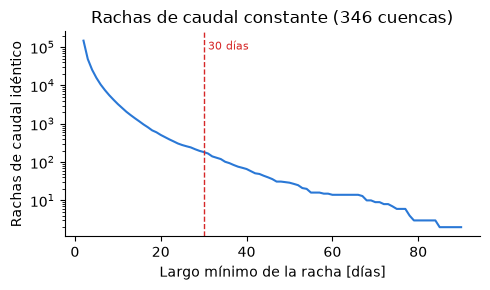

In [6]:
fig, ax = plt.subplots(figsize=(5, 3))
x = np.arange(2, 91)
ax.semilogy(x, [(rachas.largo >= m).sum() for m in x], color="#2a78d6")
ax.axvline(30, color="#d62728", ls="--", lw=1); ax.text(31, ax.get_ylim()[1] / 3, "30 días", color="#d62728", fontsize=8)
ax.set(xlabel="Largo mínimo de la racha [días]", ylabel="Rachas de caudal idéntico", title="Rachas de caudal constante (346 cuencas)")
ax.spines[["top", "right"]].set_visible(False); fig.tight_layout(); plt.show()

**Lectura y decisión.** Las rachas decaen de forma continua, sin un corte natural: hay 148.081 de 2 días y 183 de 30 o más. Por eso 30 días es una **convención conservadora** (un mes con el caudal exactamente igual no es un comportamiento natural de un río), no un umbral estadístico. Marca muy pocos días y ninguna racha de ceros, que [1] advierte que pueden ser reales. **Sensibilidad:** con 15 días se marcarían unas 980 rachas más (cerca de 18.300 días más); si el modelo resulta sensible a esto, es el parámetro a revisar.

### 3b. Picos: ¿por qué 10 veces?
Se buscan días aislados muy por encima de sus dos vecinos. El riesgo opuesto al error de sensor es borrar **crecientes reales**, que son justo lo que mide el KPI de alertas. Por eso se compara cada nivel de razón con la lluvia (CHIRPS, día del pico más el día anterior) y con el percentil 99 del caudal de su cuenca.

In [7]:
tabla = []
for lo, hi in [(3, 5), (5, 10), (10, 20), (20, 50), (50, 1e12)]:
    s = cand_spike[(cand_spike.razon > lo) & (cand_spike.razon <= hi)]
    tabla.append(dict(razon=f"({lo}, {'∞' if hi > 1e9 else hi}]", dias=len(s), cuencas=s.gauge_id.nunique(),
                      lluvia_media_2d_mm=round(s.P2d.mean(), 1), con_lluvia_10mm=round((s.P2d >= 10).mean(), 2),
                      sin_lluvia_2mm=round((s.P2d < 2).mean(), 2), sobre_p99=round((s.q_p99 > 1).mean(), 2)))
display(pd.DataFrame(tabla).set_index("razon"))
sp10 = cand_spike[cand_spike.razon > 10]
print(f"Picos con la regla de 10×: {len(sp10)} días en {sp10.gauge_id.nunique()} cuencas")
print(f"  con lluvia ≥ 10 mm (día + día previo): {100 * (sp10.P2d >= 10).mean():.0f} %   sin lluvia (< 2 mm): {100 * (sp10.P2d < 2).mean():.0f} %")
print(f"  por encima del percentil 99 de su cuenca: {100 * (sp10.q_p99 > 1).mean():.0f} %   iguales al máximo histórico: {int((sp10.q_max >= 0.999).sum())}")
print(f"  área mediana de las cuencas con picos: {area[sp10.gauge_id.unique()].median():.0f} km²  (todas: {area.median():.0f} km²)")

,dias,cuencas,lluvia_media_2d_mm,con_lluvia_10mm,sin_lluvia_2mm,sobre_p99
razon,,,,,,
"(3, 5]",9871,275,26.9,0.75,0.13,0.22
"(5, 10]",2801,189,26.9,0.74,0.14,0.34
"(10, 20]",507,74,23.9,0.73,0.12,0.43
"(20, 50]",133,32,24.4,0.78,0.08,0.45
"(50, ∞]",23,11,22.6,0.87,0.00,0.43


Picos con la regla de 10×: 663 días en 76 cuencas
  con lluvia ≥ 10 mm (día + día previo): 74 %   sin lluvia (< 2 mm): 11 %
  por encima del percentil 99 de su cuenca: 43 %   iguales al máximo histórico: 18
  área mediana de las cuencas con picos: 292 km²  (todas: 777 km²)


**Lectura.** Los días que superan 10 veces a sus vecinos **no son distintos en lluvia** de los de 3 a 10 veces, y la mayoría tiene lluvia fuerte: la regla de 10× borra, además de errores de sensor, picos que parecen crecientes reales (sobre todo en cuencas pequeñas, donde una creciente sube y baja en un día). El costo en volumen es mínimo, pero esos días son los más valiosos para el KPI de alertas de creciente.

**Decisión: se usa la opción A (10× sola).** Opciones comparadas:
- **A. 10× sola** (la de la limpieza previa).
- **B. 10× solo si no hay lluvia que la respalde** (lluvia día + día previo < 10 mm): más defendible físicamente, porque un pico sin lluvia es sospechoso.

Se elige A por tres razones: (1) reproduce exactamente las 248 series de la limpieza previa, así que los resultados son comparables con el trabajo ya hecho; (2) marca solo 663 días, el 0,016 % de los días con caudal; (3) los días no se borran: quedan en el archivo con `Caudal_estado = spike` y se pueden recuperar.

**Costo conocido.** El 74 % de esos picos tiene lluvia de 10 mm o más y 18 son el máximo histórico de su cuenca, así que una parte puede ser creciente real. Consecuencia: el modelo no ve esos días al entrenar y puede subestimar crecientes en cuencas pequeñas. **Se declara como limitación** en el reporte; si el modelo falla en las crecientes, la alternativa es la opción B, que solo cambia una condición en `marcar_caudal` de `limpiar_series.py`.

Conteo de cada opción:

In [8]:
opc = pd.DataFrame({"A: 10× sola": [len(sp10), sp10.gauge_id.nunique()],
                   "B: 10× y lluvia < 10 mm": [int((sp10.P2d < 10).sum()), sp10[sp10.P2d < 10].gauge_id.nunique()],
                   "B estricta: lluvia < 2 mm": [int((sp10.P2d < 2).sum()), sp10[sp10.P2d < 2].gauge_id.nunique()]}, index=["días marcados", "cuencas"])
display(opc)
print(f"Días de caudal con dato: {rachas.largo.sum():,}; la opción A marca el {100 * len(sp10) / rachas.largo.sum():.3f} % y la B el {100 * (sp10.P2d < 10).sum() / rachas.largo.sum():.3f} %")

,A: 10× sola,B: 10× y lluvia < 10 mm,B estricta: lluvia < 2 mm
días marcados,663,170,74
cuencas,76,45,30


Días de caudal con dato: 4,072,868; la opción A marca el 0.016 % y la B el 0.004 %


## 4. Validación contra la limpieza previa
La limpieza de `clean_timeseries/` (248 cuencas) no documentaba sus umbrales. Se aplicaron las reglas de este notebook (opción A) a los datos crudos y se compararon día por día con sus series. `codigo/limpiar_series.py` hace esta comparación al ejecutarse.

In [9]:
if PREVIA is None or not (OUT / "Hydromet_data_11027010.txt").exists():
    print("Falta la limpieza previa o las series limpias: ejecute `python codigo/limpiar_series.py`.")
else:
    prev = pd.read_csv(PREVIA / "cleaning_report.csv", dtype={"gauge_id": str})
    prev = prev[prev.kept]
    d_est = d_q = 0; d_etp = []
    n_dias = 0
    for g in prev.gauge_id:
        n = pd.read_csv(OUT / f"Hydromet_data_{g}.txt", sep="\t"); p = pd.read_csv(PREVIA / f"Hydromet_data_{g}.txt", sep="\t")
        d_est += int((n.Caudal_estado != p.Caudal_estado).sum()); d_q += int((~np.isclose(n.Caudal, p.Caudal, equal_nan=True)).sum())
        d_etp.append((n.ETP_.mean() - p.ETP_.mean()) / p.ETP_.mean() * 100); n_dias += len(n)
    print(f"Cuencas comparadas: {len(prev)}   días: {n_dias:,}")
    print(f"Días con estado de caudal distinto: {d_est}   con caudal distinto: {d_q}")
    print(f"Diferencia de la ETP media por cuenca: mediana {np.median(d_etp):.3f} %, peor caso {max(d_etp, key=abs):.2f} %")

Cuencas comparadas: 248   días: 3,171,154
Días con estado de caudal distinto: 0   con caudal distinto: 0
Diferencia de la ETP media por cuenca: mediana -0.010 %, peor caso -0.98 %


## 5. Resultado
Las 346 series limpias están en `salidas/series_limpias/` (mismas columnas que el crudo más `Caudal_estado`), con el resumen por cuenca en `salidas/series_limpias_reporte.csv`.

In [10]:
rep = pd.read_csv(RAIZ / "salidas/series_limpias_reporte.csv")
print(f"Series: {len(rep)}   días: {rep.dias.sum():,}   agregados por el calendario: {rep.dias_agregados.sum():,}")
print(f"Picos (opción A): {rep.spike_dias.sum():,}   congelados: {rep.frozen_dias.sum():,}")
print(f"Caudal válido (mediana por cuenca): {rep.q_valido_pct.median():.1f} %")

Series: 346   días: 4,347,980   agregados por el calendario: 275,112
Picos (opción A): 663   congelados: 7,366
Caudal válido (mediana por cuenca): 94.4 %


## 6. Banderas de descarte (paso 3)
Con las series ya limpias se decide qué cuencas se conservan. Una cuenca con **cualquiera** de las seis banderas se descarta. Código: `codigo/aplicar_banderas.py`.

| Bandera | Qué detecta | Cómo se obtiene | Respaldo documental |
|---|---|---|---|
| `f_q_gt_p` | caudal mayor que la lluvia (coeficiente de escorrentía > 1) | calculada aquí | principio de balance de masa; **no se encontró una fuente que excluya cuencas por este criterio** |
| `f_flatline` | caudal plano: ≥ 10 % de los días en rachas de ≥ 7 días iguales | calculada aquí; umbral inferido | el concepto sí: [1] Flat Line Test y [4]; **el umbral no está en ninguna fuente** |
| `f_regime_mismatch` | el régimen anual del caudal no coincide con el de la lluvia | criterio del equipo (limpieza previa) | **ninguno encontrado** |
| `f_nested_inconsistent` | cuenca anidada con caudales que no cuadran con la de aguas arriba | criterio del equipo | **ninguno encontrado** |
| `f_delineation` | contorno de la cuenca (área) mal trazado | criterio del equipo | práctica común comparar el área trazada con la reportada por la red de estaciones; **sin cita verificada** |
| `f_twin_mismatch` | dos estaciones casi en el mismo punto con datos distintos | criterio del equipo | **ninguno encontrado** |

**Respaldo documental, sin exagerar.** Ni el artículo de CAMELS-COL (preprint essd-2025-200), que solo describe su selección de estaciones (10 años desde 1980 y 70 % de datos), ni los manuales de control de calidad consultados describen estas seis pruebas con estos umbrales. Las banderas son **criterios físicos razonables aplicados por el equipo**, no un procedimiento publicado; así deben presentarse en el reporte. Los documentos sí respaldan los conceptos de línea plana y de pico ([1], [4]) y de comparar áreas trazadas con áreas reportadas.

Las cuatro últimas necesitan información que no está en el repositorio (comparar cuencas vecinas, régimen esperado, trazado de contornos), así que se toman de `cleaning_report.csv`.

### 6a. `f_q_gt_p`: ¿sale más agua de la que entra?
**Principio.** En el largo plazo el balance de masa de una cuenca es $P = ET + Q + \Delta S$, con $\Delta S \approx 0$; por tanto $Q \le P$ y el coeficiente de escorrentía $Q/P$ no puede superar 1. Un valor mayor indica un error en la lluvia satelital, en el caudal o en el área de la cuenca. Se calcula con la media de $Q$ (en mm/día, $Q\cdot 86{,}4/\text{área}$) y de $P$ en los días con ambos datos, y se compara con `runoff_ratio` del archivo 09.

In [11]:
import aplicar_banderas as ab
bd = ab.calcular_bandas_propias()
print(f"Coeficiente de escorrentía calculado vs `runoff_ratio` del archivo 09: correlación {bd.coef_serie.corr(bd.runoff_ratio):.3f}")
print(f"Cuencas con coef. > 1: con la serie {(bd.coef_serie > 1).sum()}   con el archivo 09 {(bd.runoff_ratio > 1).sum()}   distintas {((bd.coef_serie > 1) != (bd.runoff_ratio > 1)).sum()}")
bd["region"] = bd.gauge_id.str[0].map({"1": "Caribe", "2": "Magdalena-Cauca", "3": "Orinoco", "4": "Amazonas", "5": "Pacífico"})
t = bd.groupby("region").agg(cuencas=("gauge_id", "count"), q_gt_p=("f_q_gt_p", "sum")).reindex(["Magdalena-Cauca", "Orinoco", "Caribe", "Pacífico", "Amazonas"])
t["%"] = (100 * t.q_gt_p / t.cuencas).round(1); display(t)
print(f"Coeficiente máximo: {bd.runoff_ratio.max():.2f}")

Coeficiente de escorrentía calculado vs `runoff_ratio` del archivo 09: correlación 1.000
Cuencas con coef. > 1: con la serie 55   con el archivo 09 55   distintas 0


,cuencas,q_gt_p,%
region,,,
Magdalena-Cauca,182,10,5.5
Orinoco,57,20,35.1
Caribe,53,4,7.5
Pacífico,32,12,37.5
Amazonas,22,9,40.9


Coeficiente máximo: 14.45


**Lectura.** Las dos formas de calcularlo coinciden. La violación se concentra en las regiones más húmedas (ver tabla), lo que apunta a una subestimación sistemática de la lluvia satelital y no a fallas aisladas de medición. Todas estas cuencas se descartan: con ellas el modelo aprendería a producir más agua de la que llueve.

### 6b. `f_flatline`: caudal plano
**Idea** ([1] Flat Line Test, [4] persistencia): un río real casi nunca repite exactamente el mismo caudal varios días seguidos; si una parte importante del registro lo hace, la serie probablemente viene de un sensor atascado o de interpolación. A diferencia de `frozen` (sección 3a, que borra los días de una racha de 30 o más), esta bandera mira **toda la cuenca**: qué fracción de sus días está en rachas cortas pero frecuentes, y descarta la cuenca.

**Regla:** $\%\,\text{días en rachas de}\ \ge 7\ \text{días iguales} \ge 10\,\%$.

**De dónde salen 7 días y 10 %.** No hay umbral publicado para caudal diario. Se probaron varios largos de racha y se midió cuál separa mejor a las 19 cuencas que la limpieza previa marcó como planas del resto (AUC: 1 es separación perfecta).

In [12]:
import time
from sklearn.metrics import roc_auc_score
prev = pd.read_csv(PREVIA / "cleaning_report.csv", dtype={"gauge_id": str}).set_index("gauge_id")
marca_prev = prev.drop_flags.fillna("").str.contains("f_flatline")
LARGOS = (3, 5, 7, 10, 15, 30)
filas = []
for r in rutas:
    gid = r.stem.split("_")[-1]
    a = pd.read_csv(r, sep="\t", usecols=["Fecha", "Caudal"])
    a["Fecha"] = pd.to_datetime(a["Fecha"], format="%d/%m/%Y")
    q = a.set_index("Fecha").reindex(pd.date_range(a.Fecha.min(), a.Fecha.max())).Caudal
    filas.append({"gauge_id": gid, **{f"rachas{k}": ab.pct_en_rachas(q, k) for k in LARGOS}})
F = pd.DataFrame(filas).set_index("gauge_id")
y = marca_prev.reindex(F.index)
auc = pd.Series({f"rachas ≥ {k} días": roc_auc_score(y, F[f"rachas{k}"]) for k in LARGOS}).round(3)
print(f"Cuencas marcadas por la limpieza previa: {int(y.sum())} de {len(y)}")
display(auc.to_frame("AUC"))
a7, b7 = F.loc[y, "rachas7"], F.loc[~y, "rachas7"]
print(f"Rachas ≥ 7 días: cuencas marcadas desde {a7.min():.2f} %; no marcadas hasta {b7.max():.2f} %")
display(pd.DataFrame([dict(umbral=f"{t} %", cuencas_marcadas=int((F.rachas7 >= t).sum()), errores=int(((F.rachas7 >= t) != y).sum())) for t in (8, 9, 9.5, 10, 11, 12)]).set_index("umbral"))

Cuencas marcadas por la limpieza previa: 19 de 346


,AUC
rachas ≥ 3 días,0.986
rachas ≥ 5 días,0.996
rachas ≥ 7 días,1.000
rachas ≥ 10 días,0.996
rachas ≥ 15 días,0.985
rachas ≥ 30 días,0.912


Rachas ≥ 7 días: cuencas marcadas desde 10.13 %; no marcadas hasta 9.95 %


,cuencas_marcadas,errores
umbral,,
8 %,32,13
9 %,25,6
9.5 %,21,2
10 %,19,0
11 %,10,9
12 %,6,13


**Lectura y decisión.** Con rachas de 7 días la separación es perfecta (AUC = 1): las cuencas marcadas tienen desde 10,13 % de sus días en esas rachas y las demás hasta 9,95 %. El umbral de 10 % queda en ese hueco y no comete errores contra la limpieza previa; con 9 % o 11 % empieza a equivocarse. **Limitación honesta:** el umbral se ajustó a una lista ya existente, el hueco es angosto (9,95 a 10,13) y no hay una referencia publicada que lo confirme. Se acepta porque es una regla simple, físicamente interpretable y coincide con el criterio del equipo.

### 6c. Resultado: cuencas que se conservan

In [13]:
ab.main() if not (RAIZ / "salidas/banderas_descarte.csv").exists() else None
B = pd.read_csv(RAIZ / "salidas/banderas_descarte.csv", dtype={"gauge_id": str})
cols = ["f_q_gt_p", "f_flatline", "f_regime_mismatch", "f_nested_inconsistent", "f_delineation", "f_twin_mismatch"]
print(f"Cuencas: {len(B)}   conservadas: {int(B.conservada.sum())}   descartadas: {int((~B.conservada).sum())}")
display(pd.DataFrame({"cuencas con la bandera": B[cols].sum(), "solo esa bandera": [int(((B.n_banderas == 1) & B[c]).sum()) for c in cols]}))
print(f"Cuencas con más de una bandera: {int((B.n_banderas > 1).sum())}")
r = B.groupby("region").agg(cuencas=("gauge_id", "count"), conservadas=("conservada", "sum")).reindex(["Magdalena-Cauca", "Orinoco", "Caribe", "Pacífico", "Amazonas"])
r["% conservadas"] = (100 * r.conservadas / r.cuencas).round(0); r.loc["Total"] = [r.cuencas.sum(), r.conservadas.sum(), round(100 * r.conservadas.sum() / r.cuencas.sum())]
display(r.astype(int))
kept_prev = prev.kept.reindex(B.gauge_id).values
print(f"Coincidencia con la limpieza previa: {int((B.conservada.values == kept_prev).sum())} de {len(B)}")

Cuencas: 346   conservadas: 248   descartadas: 98


,cuencas con la bandera,solo esa bandera
f_q_gt_p,55,42
f_flatline,19,15
f_regime_mismatch,20,13
f_nested_inconsistent,13,9
f_delineation,6,0
f_twin_mismatch,5,3


Cuencas con más de una bandera: 16


,cuencas,conservadas,% conservadas
region,,,
Magdalena-Cauca,182,136,75
Orinoco,57,37,65
Caribe,53,44,83
Pacífico,32,20,62
Amazonas,22,11,50
Total,346,248,72


Coincidencia con la limpieza previa: 346 de 346


**Resultado.** Se conservan **248 cuencas** y se descartan 98. La causa más frecuente es el caudal mayor que la lluvia (55), seguida de régimen distinto (20) y caudal plano (19). La lista de cuencas para modelar está en `salidas/cuencas_modelado.csv` y el detalle de banderas por cuenca en `salidas/banderas_descarte.csv`. **No se descarta ninguna por tener pocos años de registro:** todas las conservadas tienen al menos 11 años de caudal válido, y la partición temporal se hace dentro de cada cuenca para usar las 248.

## 7. Resumen de decisiones y limitaciones

| Decisión | Por qué | Límite o costo |
|---|---|---|
| Calendario continuo, sin imputar `NaN` | Rezagos y ventanas necesitan días consecutivos; imputar mezclaría datos inventados con reales | El 6,3 % de los días no tiene dato; se excluyen con la máscara |
| ETP de Hargreaves | La ETP original está sobreestimada (≈ 2,7 veces); Hargreaves es el método estándar con solo temperatura [2], [3] | Aproximación; la latitud es la de la estación, no la de la cuenca |
| `frozen`: 30 días iguales | Caudal idéntico un mes no es natural [1], [4]; marca solo 183 rachas | El umbral es una convención: las rachas decaen sin corte natural |
| `spike`: 10× los vecinos (opción A) | Reproduce la limpieza previa; 0,016 % de los días | Puede borrar crecientes reales (74 % con lluvia ≥ 10 mm) |
| Descarte con seis banderas | Quita cuencas con datos incoherentes (Q > P, caudal plano, régimen, anidadas, contorno, gemelas) | Cuatro banderas son criterio del equipo, no calculadas aquí; el umbral de línea plana se ajustó a una lista existente |

**Estados de caudal en el archivo limpio:** `ok` (se usa), `no_data` (día agregado), `frozen` y `spike` (caudal puesto en `NaN`). Solo los días `ok` entran a la pérdida y a las métricas.